# ELEVVO NLP INTERNSHIP
# TASK 01: Sentiment Analysis on IMDb Movie Reviews

INSTALL REQUIRED LIBRARIES

In [ ]:
!pip install -q datasets nltk scikit-learn pandas numpy matplotlib

IMPORT LIBRARIES

In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk

from collections import Counter
from datasets import load_dataset
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


DOWNLOAD NLTK STOPWORDS

In [ ]:
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))

# Keep negation words because they are important for sentiment
stop_words = stop_words - {"not", "no", "nor"}

print("Stopwords downloaded successfully!")

Stopwords downloaded successfully!


LOAD IMDb DATASET

In [ ]:
dataset = load_dataset("stanfordnlp/imdb")

df = pd.DataFrame(dataset["train"])

print("\nDataset loaded successfully!")

print("\nFirst five records:")
print(df.head())

print("\nDataset shape:")
print(df.shape)


Dataset loaded successfully!

First five records:
                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0

Dataset shape:
(25000, 2)


EXPLORE DATASET


Missing values:
text     0
label    0
dtype: int64

Sentiment distribution:
label
0    12500
1    12500
Name: count, dtype: int64


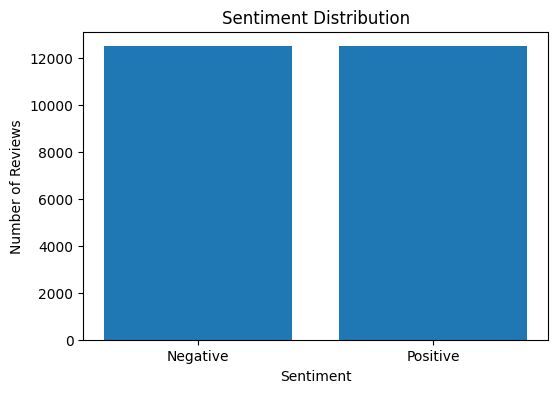

In [ ]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df["label"].value_counts())

# Label 0 = Negative
# Label 1 = Positive

sentiment_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Negative", "Positive"],
    sentiment_counts.values
)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

TEXT PREPROCESSING

In [ ]:

def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Split text into words
    words = text.split()

    # Remove stopwords
    words = [
        word for word in words
        if word not in stop_words
    ]

    # Join words again
    return " ".join(words)


df["cleaned_review"] = df["text"].apply(clean_text)

print("\nOriginal review:")
print(df["text"].iloc[0][:300])

print("\nCleaned review:")
print(df["cleaned_review"].iloc[0][:300])


Original review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h

Cleaned review:
rented curious yellow video store controversy surrounded first released also heard first seized u customs ever tried enter country therefore fan films considered controversial really see plot centered around young swedish drama student named lena wants learn everything life particular wants focus at


TRAIN-TEST SPLIT

In [ ]:

X = df["cleaned_review"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 20000
Testing samples: 5000


 TF-IDF VECTORIZATION

In [ ]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF vectorization completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)


TF-IDF vectorization completed!
Training matrix shape: (20000, 20000)
Testing matrix shape: (5000, 20000)


TRAIN LOGISTIC REGRESSION MODEL

In [ ]:

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("\nLogistic Regression model trained successfully!")


# 10. MAKE PREDICTIONS

y_pred = model.predict(X_test_tfidf)

print("\nPredictions completed!")


Logistic Regression model trained successfully!

Predictions completed!


MAKE PREDICTIONS

In [ ]:
y_pred = model.predict(X_test_tfidf)

print("\nPredictions completed!")



Predictions completed!


 MODEL EVALUATION


In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print("\nLogistic Regression Results")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)


Logistic Regression Results
Accuracy: 89.8 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.88      0.90      2500
    Positive       0.89      0.91      0.90      2500

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



CONFUSION MATRIX

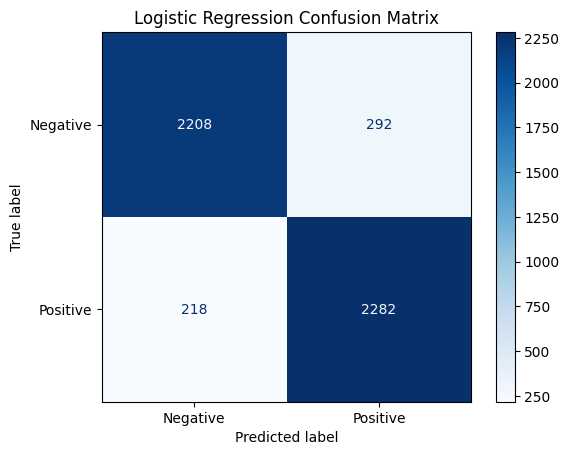

In [ ]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

VISUALIZE MOST FREQUENT POSITIVE AND NEGATIVE WORDS

In [ ]:
positive_reviews = df[df["label"] == 1]["cleaned_review"]
negative_reviews = df[df["label"] == 0]["cleaned_review"]

positive_words = Counter(
    " ".join(positive_reviews).split()
)

negative_words = Counter(
    " ".join(negative_reviews).split()
)

Top 15 positive words

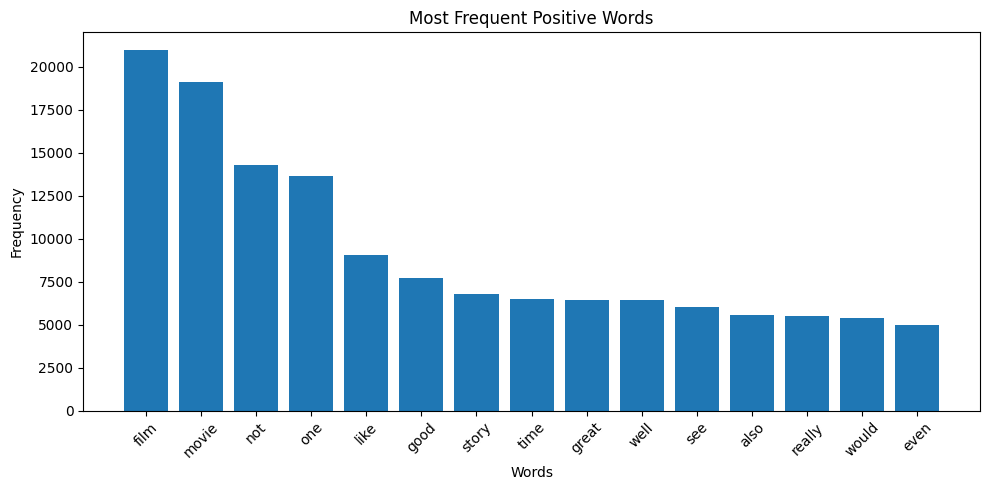

In [ ]:
top_positive = positive_words.most_common(15)

words, counts = zip(*top_positive)

plt.figure(figsize=(10, 5))
plt.bar(words, counts)
plt.title("Most Frequent Positive Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Top 15 negative words

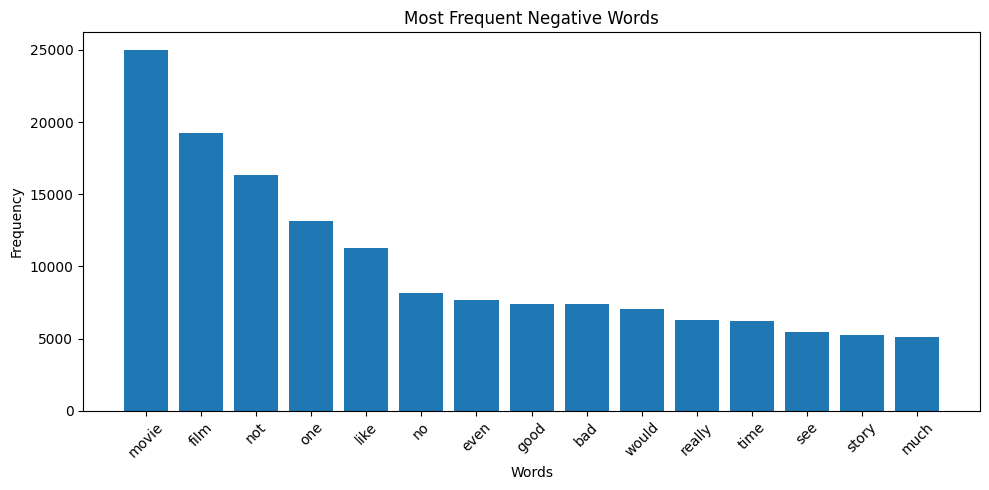

In [ ]:
top_negative = negative_words.most_common(15)

words, counts = zip(*top_negative)

plt.figure(figsize=(10, 5))
plt.bar(words, counts)
plt.title("Most Frequent Negative Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NAIVE BAYES CLASSIFIER

In [ ]:

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

nb_accuracy = accuracy_score(y_test, nb_predictions)

print("\nNaive Bayes Results")

print("Accuracy:", round(nb_accuracy * 100, 2), "%")


Naive Bayes Results
Accuracy: 87.74 %


COMPARE BOTH MODELS

In [ ]:
print("\nMODEL COMPARISON")

print(
    "Logistic Regression:",
    round(accuracy * 100, 2), "%"
)

print(
    "Naive Bayes:",
    round(nb_accuracy * 100, 2), "%"
)


MODEL COMPARISON
Logistic Regression: 89.8 %
Naive Bayes: 87.74 %


TEST WITH YOUR OWN REVIEWS

In [ ]:
def predict_sentiment(review):

    cleaned = clean_text(review)

    vectorized = tfidf.transform([cleaned])

    prediction = model.predict(vectorized)[0]

    if prediction == 1:
        result = "Positive"
    else:
        result = "Negative"

    print("\nReview:", review)
    print("Predicted Sentiment:", result)

Test

In [ ]:
predict_sentiment(
    "This movie was amazing and I really enjoyed it!"
)

predict_sentiment(
    "This movie was boring and a complete waste of time."
)



Review: This movie was amazing and I really enjoyed it!
Predicted Sentiment: Positive

Review: This movie was boring and a complete waste of time.
Predicted Sentiment: Negative
